In [2087]:
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt


class Neural_Network(object):
    def __init__(self):
        #Define Parameters
        self.inputLayerSize = 2
        self.outputLayerSize=1
        self.hiddenLayerSize=3
        
        #Define Weights
        self.W1=np.random.rand(self.inputLayerSize,self.hiddenLayerSize)
        self.W2=np.random.rand(self.hiddenLayerSize,self.outputLayerSize)

    def forward(self,X):
        #Propagate inputs through network
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.sigmoid(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        yHat = self.sigmoid(self.z3)
        return yHat
    
    def sigmoid(self, z):
        #Apply Sigmoid Activation Function
        return 1/(1+np.exp(-z))
    
    def sigmoidPrime(self,z):
        #Derivative of Sigmoid Function
        return np.exp(-z)/((1+np.exp(-z))**2)
    
    def relu(self, z):
        return np.maximum(0, z)
    
    def reluPrime(self,z):
        return 1 * (z > 0)

    def costFunctionPrimeRelu(self, X, y):
        self.yHat=self.forward(X)
        delta3 = np.multiply(-(y-self.yHat),self.reluPrime(self.z3))
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.reluPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2

    def forwardRelu(self,X):
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.relu(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        yHat = self.relu(self.z3)
        return yHat

    def costFunction(self, X, y):
        #Compute Cost Function with weights already stored in class
        self.yHat=self.forward(X)
        J=0.5*sum((y-self.yHat)**2)
        return J

    def costFunctionRelu(self, X,y):
        self.yHat=self.forwardRelu(X)
        J=0.5*sum((y-self.yHat)**2)
        return J
    
    def costFunctionPrime(self, X, y):
        #Compute derivatives with respect to W1 and W2
        self.yHat=self.forward(X)
        delta3 = np.multiply(-(y-self.yHat),self.sigmoidPrime(self.z3))
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.sigmoidPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2


In [2088]:
X=np.array(([3,5],[5,1],[10,1]),dtype=float)
y=np.array(([75],[80],[93]),dtype=float)

In [2089]:
X


array([[ 3.,  5.],
       [ 5.,  1.],
       [10.,  1.]])

In [2090]:
y

array([[75.],
       [80.],
       [93.]])

In [2091]:
X=X/np.amax(X,axis=0)
y=y/100

In [2092]:
X,y


(array([[0.3, 1. ],
        [0.5, 0.2],
        [1. , 0.2]]),
 array([[0.75],
        [0.8 ],
        [0.93]]))

In [2093]:
NN=Neural_Network()

In [2094]:
yH=NN.forward(X)

In [2095]:
yH

array([[0.7473251 ],
       [0.72688763],
       [0.74672515]])

In [2096]:
y

array([[0.75],
       [0.8 ],
       [0.93]])

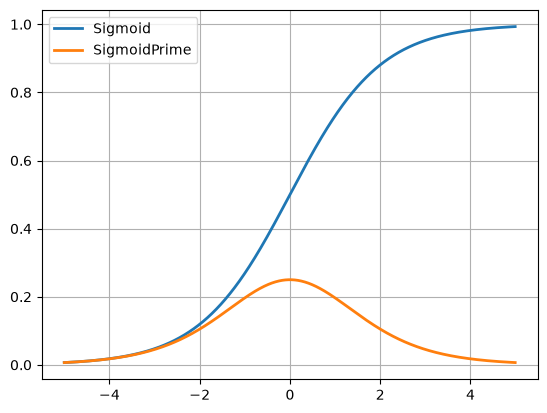

In [2097]:
testValues=np.arange(-5,5,0.01)
plt.plot(testValues,NN.sigmoid(testValues),linewidth=2)
plt.plot(testValues, NN.sigmoidPrime(testValues),linewidth=2)
plt.grid(1)
plt.legend(['Sigmoid','SigmoidPrime'])


In [2098]:
NN=Neural_Network()

In [2099]:
cost1=NN.costFunction(X,y)

In [2100]:
cost1

array([0.02545769])

In [2101]:
dJdW1,dJdW2=NN.costFunctionPrime(X,y)

In [2102]:
dJdW1

array([[-0.01080017, -0.00341034, -0.00196179],
       [-0.00386223, -0.00116008, -0.00065032]])

In [2103]:
dJdW2

array([[-0.04448964],
       [-0.04343672],
       [-0.03730974]])

In [2104]:
scalar= 3
NN.W1 = NN.W1+scalar*dJdW1
NN.W2 = NN.W2+scalar*dJdW2
cost2 = NN.costFunction(X,y)
print (cost1,cost2)

[0.02545769] [0.04656755]


In [2105]:
scalar= 3 #this is our alpha
NN.W1 = NN.W1-scalar*dJdW1
NN.W2 = NN.W2-scalar*dJdW2
cost3 = NN.costFunction(X,y)
print (cost2,cost3)

[0.04656755] [0.02545769]


In [2106]:
# NN.W1 = NN.W1 + scalar*(NN.yHat-NN.a3)*NN.sigmoidPrime(NN.z3)*array([NN.X[0,0], NN.X[0,1], NN.X[0,2]],[NN.X[1,0], NN.X[1,1], NN.X[1,2]])
# NN.W1

[[0.8222624  0.59901014 0.07640244]
 [0.34544326 0.7173561  0.7784425 ]] [[0.9798931 ]
 [0.29678258]
 [0.15409401]]


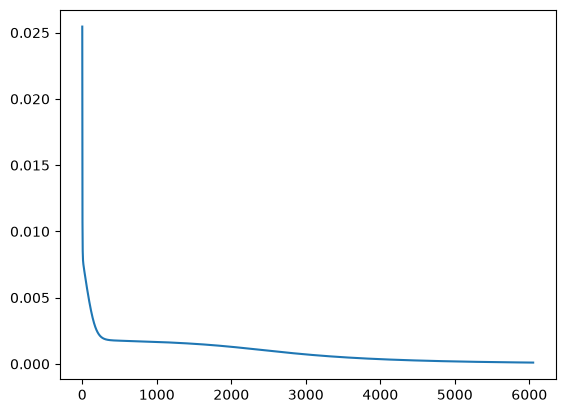

In [2107]:
def minimize(alpha, accuracyPoop):
    W1_init = NN.W1
    W2_init = NN.W2
    print(W1_init,W2_init)
    cost = NN.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:

        dJdW1, dJdW2 = NN.costFunctionPrime(X, y)

        NN.W1 = NN.W1-alpha*dJdW1
        NN.W2 = NN.W2-alpha*dJdW2

        cost = NN.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr

cost_arr = (minimize(2, .0001))

# print(cost_arr)
plt.plot(cost_arr)

In [2108]:
sigmoid_loss = NN.forward(X)-y

In [2109]:

class ReluNeural_Network(object):
    def __init__(self):
        #Define Parameters
        self.inputLayerSize = 2
        self.outputLayerSize=1
        self.hiddenLayerSize=3

        #Define Weights
        self.W1=np.random.rand(self.inputLayerSize,self.hiddenLayerSize)
        self.W2=np.random.rand(self.hiddenLayerSize,self.outputLayerSize)

    def forward(self,X):
        #Propagate inputs through network
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.relu(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        yHat = self.sigmoid(self.z3)
        return yHat

    def relu(self, z):
        return np.maximum(0, z)

    def reluPrime(self,z):
        return 1 * (z > 0)

    def sigmoid(self, z):
        #Apply Sigmoid Activation Function
        return 1/(1+np.exp(-z))

    def costFunction(self, X, y):
        #Compute Cost Function with weights already stored in class
        self.yHat=self.forward(X)
        J=0.5*sum((y-self.yHat)**2)
        return J


    def costFunctionPrime(self, X, y):
        #Compute derivatives with respect to W1 and W2
        self.yHat=self.forward(X)
        delta3 = np.multiply(-(y-self.yHat),self.sigmoidPrime(self.z3))
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.reluPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2

    def sigmoidPrime(self,z):
        #Derivative of Sigmoid Function
        return np.exp(-z)/((1+np.exp(-z))**2)


[[0.32624766 0.08670614 0.36983847]
 [0.74788533 0.8471618  0.93508131]] [[0.13540669]
 [0.84063156]
 [0.22622798]]


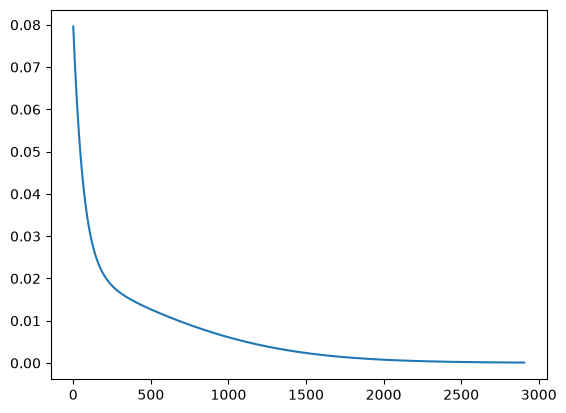

In [2110]:
ReluNN = ReluNeural_Network()

def minimizeRelu(alpha, accuracyPoop, ReluNN):
    W1_init = ReluNN.W1
    W2_init = ReluNN.W2
    print(W1_init,W2_init)
    cost = ReluNN.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:

        dJdW1, dJdW2 = ReluNN.costFunctionPrime(X, y)

        ReluNN.W1 = ReluNN.W1-alpha*dJdW1
        ReluNN.W2 = ReluNN.W2-alpha*dJdW2

        cost = ReluNN.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr

cost_arrRelu = (minimizeRelu(.05, .0001, ReluNN))

# print(cost_arr)
plt.plot(cost_arrRelu)

In [2111]:
relu_loss = ReluNN.forward(X)-y

In [2112]:
class ReluNeural_Network_Extra(object):
    def __init__(self, size):
        #Define Parameters
        self.inputLayerSize = 2
        self.outputLayerSize=1
        self.hiddenLayerSize=3
        self.hiddenLayer_2_Size = size

        #Define Weights
        self.W1=np.random.rand(self.inputLayerSize,self.hiddenLayerSize)
        self.W2=np.random.rand(self.hiddenLayerSize,self.hiddenLayer_2_Size)
        self.W3=np.random.rand(self.hiddenLayer_2_Size,self.outputLayerSize)

    def forward(self,X):
        #Propagate inputs through network
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.relu(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        self.a3 = self.relu(self.z3)
        self.z4 = np.dot(self.a3, self.W3)
        yHat = self.sigmoid(self.z4)
        return yHat

    def relu(self, z):
        return np.maximum(0, z)

    def reluPrime(self,z):
        return 1 * (z > 0)

    def sigmoid(self, z):
        #Apply Sigmoid Activation Function
        return 1/(1+np.exp(-z))

    def costFunction(self, X, y):
        #Compute Cost Function with weights already stored in class
        self.yHat=self.forward(X)
        J=0.5*sum((y-self.yHat)**2)
        return J


    def costFunctionPrime(self, X, y):
        #Compute derivatives with respect to W1 and W2
        self.yHat=self.forward(X)
        delta4 = np.multiply(-(y-self.yHat), self.sigmoidPrime(self.z4))
        dJdW3=np.dot(self.a3.T, delta4)
        delta3 = np.dot(delta4, self.W3.T)* self.reluPrime(self.z3)
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.reluPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2, dJdW3

    def sigmoidPrime(self,z):
        #Derivative of Sigmoid Function
        return np.exp(-z)/((1+np.exp(-z))**2)



[[0.52665043 0.31960864 0.01030058]
 [0.21285336 0.88098822 0.68715074]] [[0.36353466 0.66514873 0.2283669 ]
 [0.71321307 0.51104432 0.13516043]
 [0.95226591 0.32003549 0.15998163]]


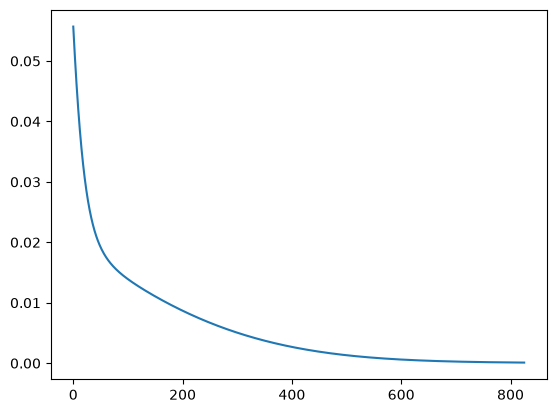

In [2113]:
ReluNN_Extra_3 = ReluNeural_Network_Extra(3)

def minimizeRelu_Extra(alpha, accuracyPoop):
    W1_init = ReluNN_Extra_3.W1
    W2_init = ReluNN_Extra_3.W2
    print(W1_init, W2_init)
    cost = ReluNN_Extra_3.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:
        dJdW1, dJdW2, dJdW3 = ReluNN_Extra_3.costFunctionPrime(X, y)

        ReluNN_Extra_3.W1 = ReluNN_Extra_3.W1 - alpha * dJdW1
        ReluNN_Extra_3.W2 = ReluNN_Extra_3.W2 - alpha * dJdW2
        ReluNN_Extra_3.W3 = ReluNN_Extra_3.W3 - alpha * dJdW3

        cost = ReluNN_Extra_3.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr


cost_arrRelu_Extra = (minimizeRelu_Extra(.1, .0001))

# print(cost_arr)
plt.plot(cost_arrRelu_Extra)


In [2114]:
three_loss = ReluNN_Extra_3.forward(X) - y

[[0.05517128 0.06213965 0.42274839]
 [0.42022115 0.84582686 0.02668432]] [[0.02814203 0.05975917 0.06686691 0.72320386 0.86581991 0.38725515
  0.51835573 0.59729978 0.10748814 0.97413927]
 [0.36424107 0.50546926 0.69324909 0.10216761 0.03185779 0.31725143
  0.67714043 0.84405115 0.44993083 0.15841705]
 [0.83400175 0.5869584  0.18254658 0.54024196 0.94892987 0.68295562
  0.15952612 0.1474976  0.94959151 0.5790284 ]]


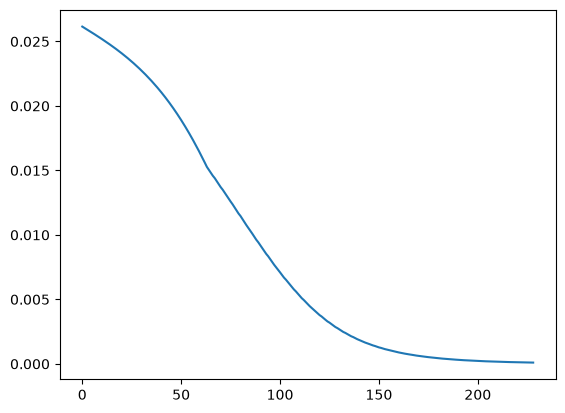

In [2115]:
ReluNN_Extra_10 = ReluNeural_Network_Extra(10)

def minimizeRelu_Extra(alpha, accuracyPoop, ReluNN_Extra_10):
    W1_init = ReluNN_Extra_10.W1
    W2_init = ReluNN_Extra_10.W2
    print(W1_init, W2_init)
    cost = ReluNN_Extra_10.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:
        dJdW1, dJdW2, dJdW3 = ReluNN_Extra_10.costFunctionPrime(X, y)

        ReluNN_Extra_10.W1 = ReluNN_Extra_10.W1 - alpha * dJdW1
        ReluNN_Extra_10.W2 = ReluNN_Extra_10.W2 - alpha * dJdW2
        ReluNN_Extra_10.W3 = ReluNN_Extra_10.W3 - alpha * dJdW3

        cost = ReluNN_Extra_10.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr


cost_arrRelu_Extra_10= (minimizeRelu_Extra(.1, .0001, ReluNN_Extra_10))

# print(cost_arr)
plt.plot(cost_arrRelu_Extra_10)



In [2116]:
ten_loss = ReluNN_Extra_10.forward(X) - y

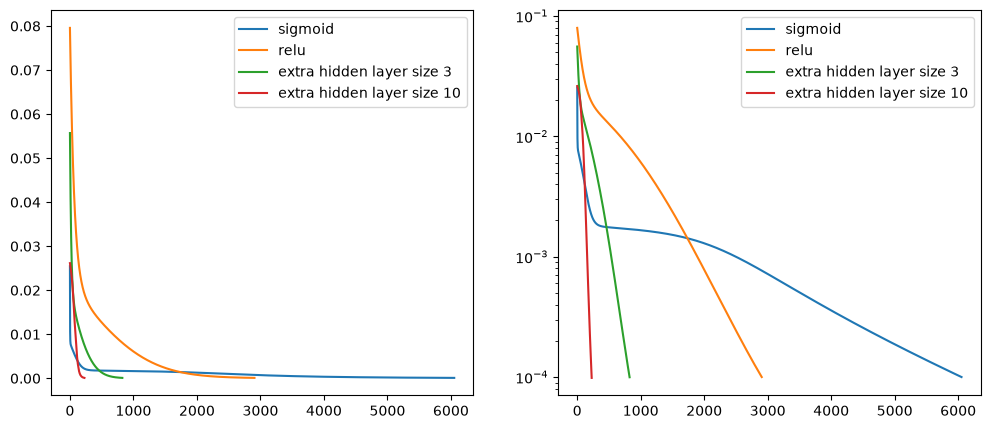

In [2117]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

for ax in (ax1, ax2):
    ax.plot(cost_arr, label = "sigmoid")
    ax.plot(cost_arrRelu, label = "relu")
    ax.plot(cost_arrRelu_Extra, label = "extra hidden layer size 3")
    ax.plot(cost_arrRelu_Extra_10, label = "extra hidden layer size 10")
    ax.legend()

ax2.set_yscale('log')

plt.show()

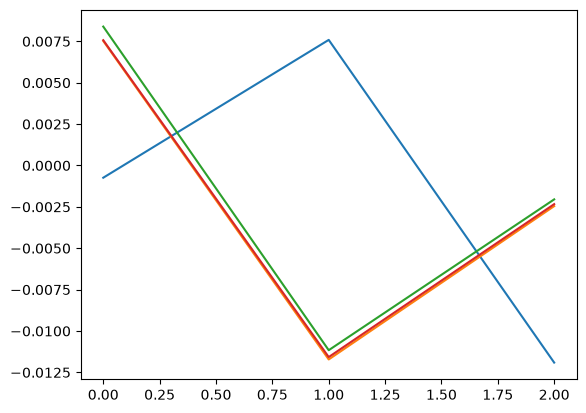

In [2118]:
plt.plot(sigmoid_loss)
plt.plot(relu_loss)
plt.plot(three_loss)
plt.plot(ten_loss)
plt.show()

[[ 0.70694923  1.36652631  0.9033125 ]
 [ 0.49074739 -0.00492895  0.58031736]] [[0.30556974]
 [1.35902336]
 [0.43924451]]
[[ 0.70694923  1.36652631  0.9033125 ]
 [ 0.49074739 -0.00492895  0.58031736]] [[0.30556974]
 [1.35902336]
 [0.43924451]]


/var/folders/sg/b9hsvlk936961f7lrslrrx2c0000gn/T/ipykernel_1475/891461494.py:29: RuntimeWarning: overflow encountered in multiply
  tester.W2 = (100-i)* piv_W2 + i * Sys_2.W2


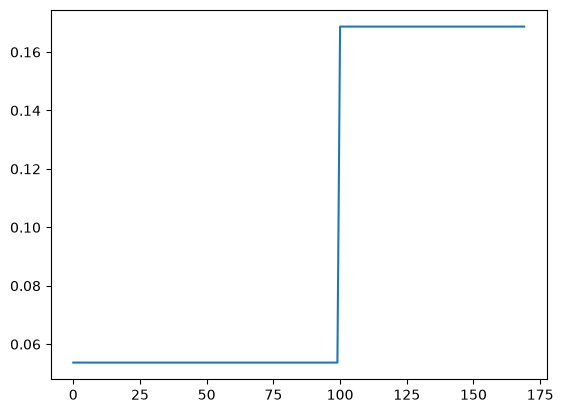

In [2119]:
Sys_1 = ReluNN
Sys_2 = ReluNN

Sol_1 = minimizeRelu(.1, .0001, Sys_1)
Sol_2 = minimizeRelu(.1, .0001,Sys_2)

def linear_int(Sys_1, Sys_2):
    piv_W1 = .5*(Sys_1.W1+Sys_2.W1)
    piv_W1_mirror = piv_W1
    piv_W2 = .5*(Sys_1.W2+Sys_2.W2)
    piv_W2_mirror = piv_W2
    mirror = ReluNN
    for i in range (500):
        mirror.W1 = piv_W1_mirror
        mirror.W2 = piv_W2_mirror
        slope_W1, slope_W2 = mirror.costFunctionPrime(X,y)
        piv_W1 = piv_W1 - 5*slope_W1
        piv_W2 = piv_W2 - 5*slope_W2
    costs = []
    iterations = []
    tester = ReluNN
    for i in range ( 0,200, 1) :
        if i < 100 :
            tester.W1 = (100-i)* Sys_1.W1 + i * piv_W1
            tester.W2 = (100-i)* Sys_1.W2 + i * piv_W2
        else:
            change = i-100
            tester.W1 = (100-i)* piv_W1 + change * Sys_2.W1
            tester.W2 = (100-i)* piv_W2 + i * Sys_2.W2
        costs.append(tester.costFunction(X,y))
        iterations.append(i)
    plt.plot(iterations, costs)

linear_int(Sys_1, Sys_2)